# Algoritmo di discesa del gradiente

Sia $f: \mathbf{R}^2 \rightarrow \mathbf{R}$, definita nel seguente modo:

$$ f(x, y) = x^2 + y^2 $$

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm

# definizione funzione
def f(x):
    return x[0]**2 + x[1]**2

Calcolando il gradiente, si ottiene:

$$
\nabla f = \left( 2x, 2y \right)
$$

In [36]:
# definizione gradiente
def f_gradient(x):
    return np.array([2 * x[0], 2 * x[1]])

def f_alt_gradient(x, y):
    return np.array([2 * x, 2 * y])

Creiamo una meshgrid per visualizzare la funzione:

In [ ]:
# meshgrid
lin_x = np.linspace(-5, 5)
lin_y = np.linspace(-5, 5)

print(lin_x.shape)
print(lin_y.shape)

#equivale a x, y = ...
xy = np.meshgrid(lin_x, lin_y)

print(xy[0].shape)
print(xy[1].shape)

#equivale a xy = ...
x, y = np.meshgrid(lin_x, lin_y)


(50,)
(50,)
(50, 50)
(50, 50)


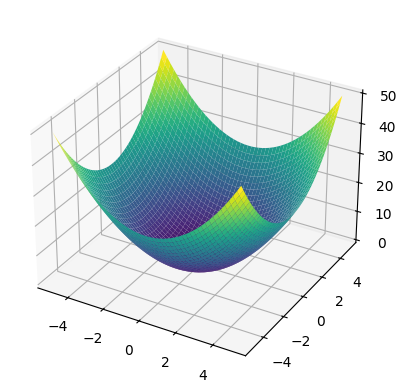

In [35]:
# plot della funzione

# Crea gli assi per la proiezione 3D
ax = plt.axes(projection='3d')

ax.plot_surface(*xy, f(xy), cmap=cm.viridis)

L'algoritmo iterativo di discesa del gradiente è definito nel seguente modo:

$$
\begin{cases}
x_0 &= a\\
x_{k+1} &= x_k - \eta \nabla f(x_k) 
\end{cases}
$$

dove $a$ è un punto nel dominio di $f$ e $\eta \in \mathbf{R}$, $\eta > 0$ un iperparametro dell'algoritmo. 

In [19]:
# implementazione algormo di discesa del gradiente

def gradient_descent(x_0, eta, iter):
    x = [x_0]

    for _ in range(iter - 1):
        # x[-1], vuol dire ultimo elemento della lista

        x_k = x[-1] - eta * f_gradient(x[-1])

        x.append(x_k)

    return np.array(x).transpose()

Applichiamo il metodo iterativo per $n = 100$ iterazioni e con $\eta = 0.1$, partendo dal punto $x_0 = (-5, 5)$

(2, 100)


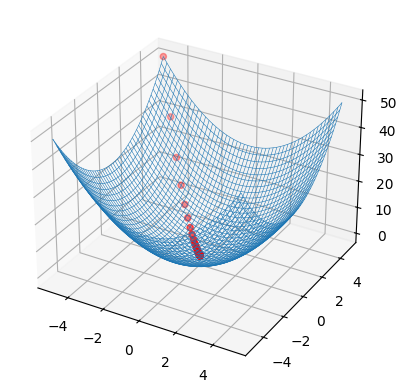

In [43]:
# plot del percorso di discesa del gradiente

N_ITER: int = 100
eta = 0.1
x_0 = np.array([-5, 5])

min_x = gradient_descent(x_0, eta, N_ITER)

print(min_x.shape)

#print(min_x)


ax2 = plt.axes(projection="3d")

ax2.plot_wireframe(*xy, f(xy), linewidth=0.4)
ax2.scatter(*min_x, f(min_x), c="r")

plt.show()


Per ridurre il numero di iterazioni, si può indicare una condizione di uscita. Ad esempio, quando il valore calcolato $y$ è sufficientemente vicino al valore ideale $y^*$ cui vorremmo arrivare. Usiamo quindi la metrica euclidea su $\mathbf{R}$:

$$
\text{errore}(y, y^*) = \left| y - y^* \right|
$$

In [ ]:
# condizione di uscita

In [50]:
def errore(x, y):
    return np.abs(x - y)

# plot della funzione e percorso di discesa del gradiente
def cerca_minimo_err(x_0, eta, iterazioni):
    # conosciamo il minimo locale della funzione a priori
    min_locale = 0

    epsilon = 0.0001 # precisione desiderata

    x = [x_0]

    i = 0

    while errore(f(x[-1]), min_locale) > epsilon and i < iterazioni:
        x_k = x[-1] - eta * f_gradient(x[-1])

        x.append(x_k)

        i += 1

    print("Numero di iterazioni:", i)

    return np.array(x).transpose()


Numero di iterazioni: 30


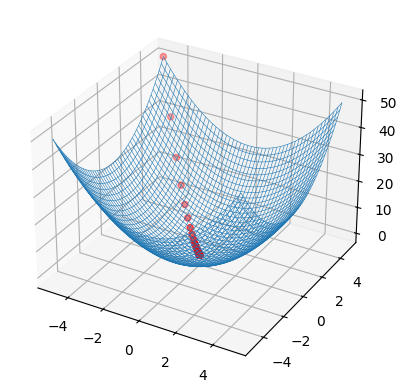

In [51]:
min_x = cerca_minimo_err(x_0, eta, N_ITER)

ax3 = plt.axes(projection="3d")

ax3.plot_wireframe(*xy, f(xy), linewidth=0.4)
ax3.scatter(*min_x, f(min_x), c="r")

plt.show()
